дз1 steel plates faults

7 классов

https://archive.ics.uci.edu/dataset/198/steel+plates+faults

гипотезы до экспериментов

масштабирование улучшит f1 macro логистической регрессии

масштабирование изменит f1 macro дерева не больше чем на 0,01

у дерева без ограничения глубины будет больше разрыв между обучением и валидацией, чем при глубине 3, 5 и 10

подбор c улучшит логистическую регрессию на тесте относительно c=1

отбор 15 признаков снизит f1 macro не больше чем на 0,02

веса классов balanced улучшат f1 macro логистической регрессии

загрузка данных

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
DATA_DIR = Path('data')
columns = (DATA_DIR / 'Faults27x7_var').read_text().split()
raw = pd.read_csv(DATA_DIR / 'Faults.NNA', sep='\\s+', header=None, names=columns)
print('размер:', raw.shape)
display(raw.head())

размер: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [2]:
feature_columns = columns[:27]
target_columns = columns[27:]
target_flags = raw[target_columns]
assert target_flags.isin([0, 1]).all().all()
assert target_flags.sum(axis=1).eq(1).all()
X = raw[feature_columns].copy()
y = target_flags.idxmax(axis=1).rename('target')
df = X.assign(target=y)
print('объектов:', len(X))
print('признаков:', X.shape[1])
print('классов:', y.nunique())
display(df.head())

объектов: 1941
признаков: 27
классов: 7


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,target
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry


In [3]:
print('пропусков:', int(raw.isna().sum().sum()))
print('дубликатов строк:', int(raw.duplicated().sum()))
print('дубликатов x:', int(X.duplicated().sum()))
counts = y.value_counts()
summary = counts.rename('количество').to_frame()
summary['доля, %'] = (counts / len(y) * 100).round(2)
display(summary)
print('max/min классов:', round(counts.max() / counts.min(), 2))

пропусков: 0
дубликатов строк: 0
дубликатов x: 0


,количество,"доля, %"
target,,
Other_Faults,673,34.67
Bumps,402,20.71
K_Scatch,391,20.14
Z_Scratch,190,9.79
Pastry,158,8.14
Stains,72,3.71
Dirtiness,55,2.83


max/min классов: 12.24


train/test 80/20

cv 5

f1 macro

In [4]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42
(X_train, X_test, y_train, y_test) = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('train:', X_train.shape)
print('test:', X_test.shape)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(y_train) == set(y_test) == set(y)

train: (1552, 27)
test: (389, 27)


In [5]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, classification_report, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train))
SCORING = {'f1_macro': 'f1_macro', 'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy'}
(records, fold_records, convergence_records) = ({}, {}, [])

def logistic(scale=True, C=1, class_weight=None, k='all'):
    return Pipeline([('scale', StandardScaler() if scale else 'passthrough'), ('select', SelectKBest(f_classif, k=k) if k != 'all' else 'passthrough'), ('clf', OneVsRestClassifier(LogisticRegression(solver='liblinear', C=C, class_weight=class_weight, max_iter=10000, tol=0.0001, random_state=RANDOM_STATE)))])

def evaluate_cv(name, estimator):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=1, error_score='raise')
    messages = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
    convergence_records.append({'experiment': name, 'convergence_warnings': len(messages)})
    records[name] = {'CV F1 macro': scores['test_f1_macro'].mean(), 'CV std': scores['test_f1_macro'].std(ddof=1), 'Train F1 macro': scores['train_f1_macro'].mean(), 'CV accuracy': scores['test_accuracy'].mean(), 'CV balanced accuracy': scores['test_balanced_accuracy'].mean()}
    fold_records[name] = scores['test_f1_macro'].tolist()
    return records[name]

def paired_table(a, b):
    return pd.DataFrame({a: fold_records[a], b: fold_records[b], 'разница второго и первого': np.array(fold_records[b]) - np.array(fold_records[a])}, index=pd.Index(range(1, 6), name='фолд'))
print('фолдов:', len(cv), 'объектов на обучении:', len(X_train))

фолдов: 5 объектов на обучении: 1552


анализ обучающих данных

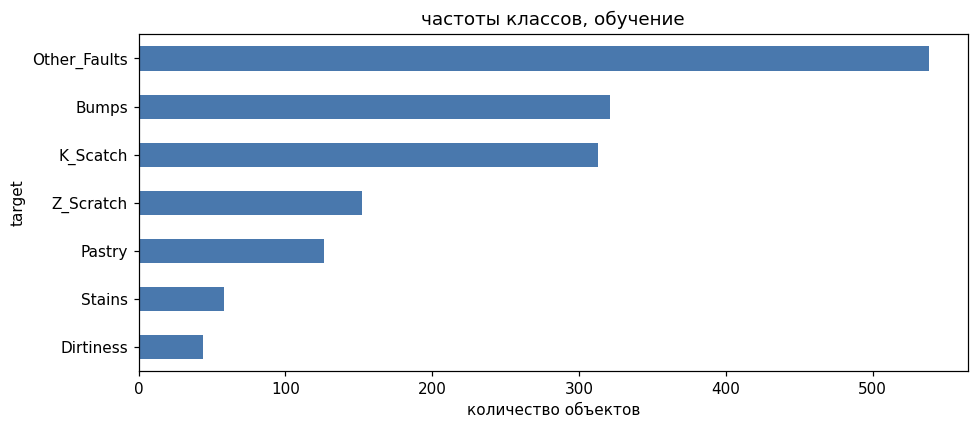

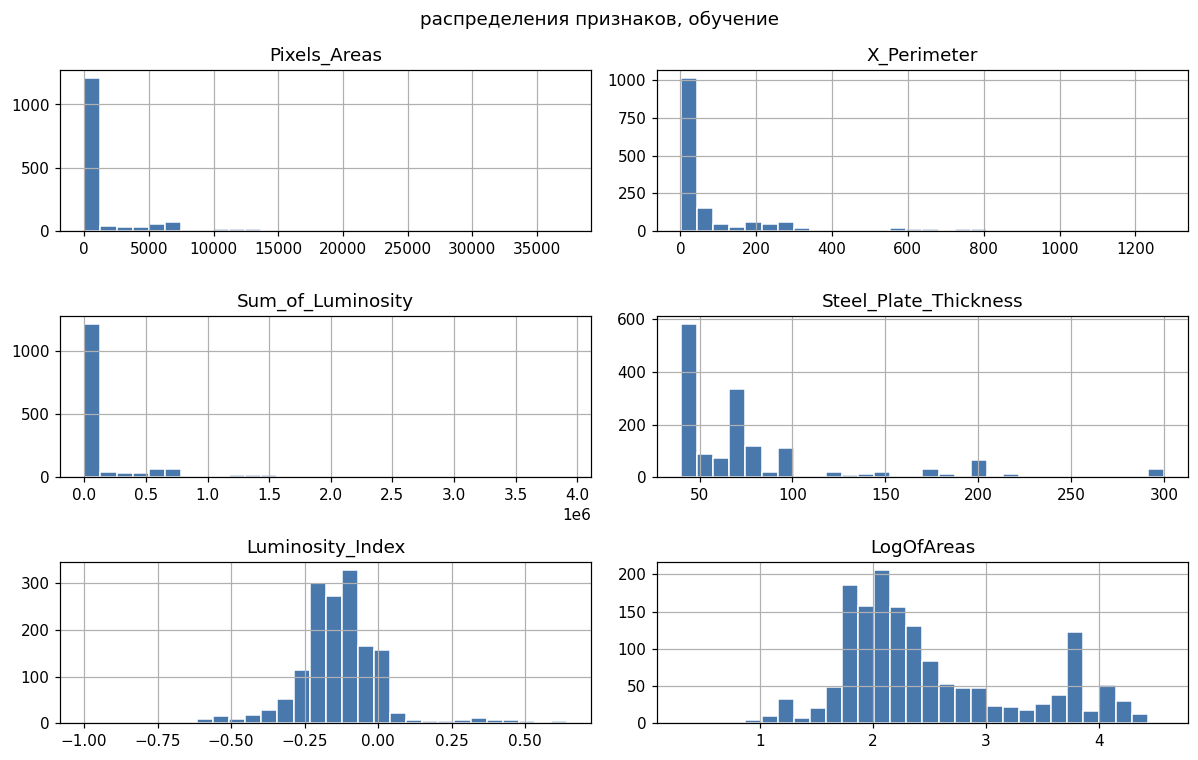

,min,max,std
X_Minimum,0.000,1.705000e+03,515.218
X_Maximum,4.000,1.713000e+03,492.280
Y_Minimum,6712.000,1.298766e+07,1811260.019
Y_Maximum,6724.000,1.298769e+07,1811258.419
Pixels_Areas,2.000,3.733400e+04,4007.856
X_Perimeter,2.000,1.275000e+03,192.130
Y_Perimeter,1.000,9.030000e+02,119.202
Sum_of_Luminosity,250.000,3.918209e+06,459112.724
Minimum_of_Luminosity,0.000,2.030000e+02,32.456
Maximum_of_Luminosity,37.000,2.530000e+02,18.980


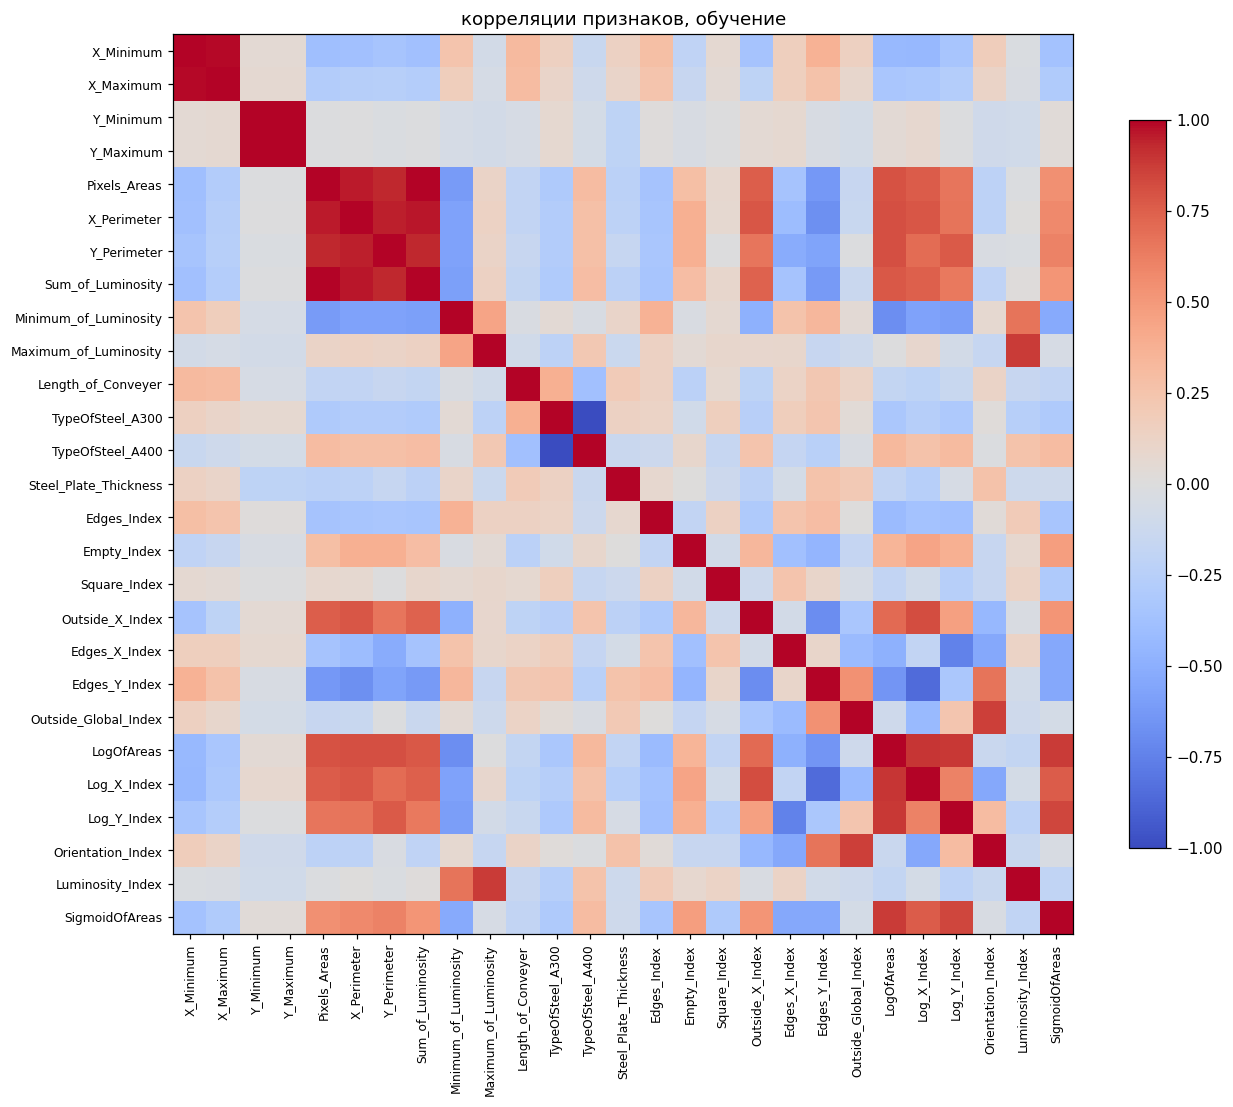

,,корреляция
TypeOfSteel_A300,TypeOfSteel_A400,-1.000000
Y_Minimum,Y_Maximum,1.000000
Pixels_Areas,Sum_of_Luminosity,0.996622
X_Minimum,X_Maximum,0.987517
X_Perimeter,Sum_of_Luminosity,0.961334
Pixels_Areas,X_Perimeter,0.960309
X_Perimeter,Y_Perimeter,0.952274
Y_Perimeter,Sum_of_Luminosity,0.935003
Pixels_Areas,Y_Perimeter,0.933444


пропусков в обучении: 0
постоянные признаки: []


In [6]:
(fig, ax) = plt.subplots(figsize=(9, 4))
y_train.value_counts().sort_values().plot.barh(ax=ax, color='#4978ad')
ax.set(title='частоты классов, обучение', xlabel='количество объектов')
fig.tight_layout()
plt.show()
features_to_plot = ['Pixels_Areas', 'X_Perimeter', 'Sum_of_Luminosity', 'Steel_Plate_Thickness', 'Luminosity_Index', 'LogOfAreas']
X_train[features_to_plot].hist(bins=30, figsize=(11, 7), color='#4978ad', edgecolor='white')
plt.suptitle('распределения признаков, обучение')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'min': X_train.min(), 'max': X_train.max(), 'std': X_train.std()}).round(3))
corr = X_train.corr()
(fig, ax) = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.set_title('корреляции признаков, обучение')
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
correlated_pairs = upper.stack().rename('корреляция').to_frame()
correlated_pairs = correlated_pairs.loc[correlated_pairs['корреляция'].abs() > 0.9]
display(correlated_pairs.sort_values('корреляция', key=abs, ascending=False))
print('пропусков в обучении:', X_train.isna().sum().sum())
print('постоянные признаки:', X_train.columns[X_train.nunique() <= 1].tolist())

гипотеза 1: масштабирование lr

In [7]:
evaluate_cv('LR raw', logistic(scale=False))
evaluate_cv('LR scaled', logistic())
display(pd.DataFrame(records).T.round(4))
display(paired_table('LR raw', 'LR scaled').round(4))
h1_delta = records['LR scaled']['CV F1 macro'] - records['LR raw']['CV F1 macro']
display(pd.DataFrame(convergence_records))

,CV F1 macro,CV std,Train F1 macro,CV accuracy,CV balanced accuracy
LR raw,0.3461,0.0166,0.3623,0.5290,0.3800
LR scaled,0.7003,0.0306,0.7303,0.7049,0.6931


,LR raw,LR scaled,разница второго и первого
фолд,,,
1,0.3645,0.7162,0.3518
2,0.3385,0.6814,0.3429
3,0.3338,0.7036,0.3698
4,0.3301,0.6605,0.3304
5,0.3636,0.7397,0.3760


,experiment,convergence_warnings
0,LR raw,0
1,LR scaled,0


подтвердилась, f1 macro +0,3542

гипотезы 2 и 3: дерево

,Tree depth 5,Tree depth 5 scaled,разница второго и первого
фолд,,,
1,0.5864,0.5864,0.0
2,0.5757,0.5757,0.0
3,0.6143,0.6143,0.0
4,0.5578,0.5578,0.0
5,0.5715,0.5715,0.0


,CV F1 macro,CV std,Train F1 macro,CV accuracy,CV balanced accuracy,Train minus CV
Tree depth 3,0.4081,0.0186,0.4193,0.5412,0.4640,0.0111
Tree depth 5,0.5811,0.0212,0.5969,0.6443,0.5860,0.0157
Tree depth 10,0.7309,0.0221,0.9046,0.7287,0.7259,0.1737
Tree depth None,0.7259,0.0246,1.0000,0.7120,0.7371,0.2741


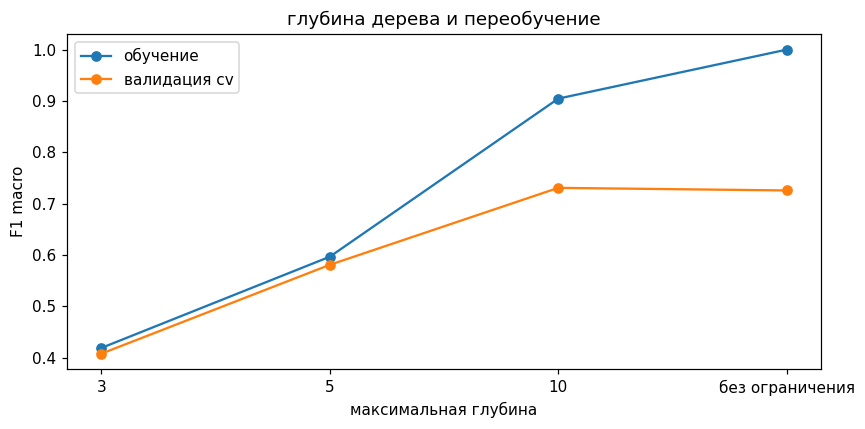

In [8]:
tree5 = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
evaluate_cv('Tree depth 5', tree5)
evaluate_cv('Tree depth 5 scaled', Pipeline([('scale', StandardScaler()), ('clf', clone(tree5))]))
display(paired_table('Tree depth 5', 'Tree depth 5 scaled').round(4))
h2_delta = records['Tree depth 5 scaled']['CV F1 macro'] - records['Tree depth 5']['CV F1 macro']
depth_names = []
for depth in [3, 5, 10, None]:
    name = f'Tree depth {depth}'
    depth_names.append(name)
    if name not in records:
        evaluate_cv(name, DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
depth_table = pd.DataFrame({n: records[n] for n in depth_names}).T
depth_table['Train minus CV'] = depth_table['Train F1 macro'] - depth_table['CV F1 macro']
display(depth_table.round(4))
(fig, ax) = plt.subplots(figsize=(8, 4))
ax.plot(['3', '5', '10', 'без ограничения'], depth_table['Train F1 macro'], marker='o', label='обучение')
ax.plot(['3', '5', '10', 'без ограничения'], depth_table['CV F1 macro'], marker='o', label='валидация cv')
ax.set(xlabel='максимальная глубина', ylabel='F1 macro', title='глубина дерева и переобучение')
ax.legend()
fig.tight_layout()
plt.show()
h3_ok = bool(depth_table.loc['Tree depth None', 'Train minus CV'] > depth_table.iloc[:3]['Train minus CV'].max())

2: подтвердилась, разница 0

3: подтвердилась, максимальный разрыв train/cv без ограничения глубины

гипотеза 4: подбор c

In [9]:
lr_search = GridSearchCV(logistic(), {'clf__estimator__C': [0.01, 0.1, 1, 10, 100]}, scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise', return_train_score=True)
lr_search.fit(X_train, y_train)
lr_grid = pd.DataFrame(lr_search.cv_results_)
display(lr_grid[['param_clf__estimator__C', 'mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']].round(4))
print('лучшее c:', lr_search.best_params_)
print('лучший cv f1 macro:', round(lr_search.best_score_, 4))

,param_clf__estimator__C,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,0.01,0.5357,0.5106,0.0213,5
1,0.10,0.6431,0.6240,0.0120,4
2,1.00,0.7303,0.7003,0.0274,3
3,10.00,0.7450,0.7129,0.0198,2
4,100.00,0.7570,0.7150,0.0118,1


лучшее c: {'clf__estimator__C': 100}
лучший cv f1 macro: 0.715


гипотеза 5: 15 признаков

In [10]:
evaluate_cv('LR selected 15', logistic(k=15))
display(paired_table('LR scaled', 'LR selected 15').round(4))
h5_delta = records['LR selected 15']['CV F1 macro'] - records['LR scaled']['CV F1 macro']
h5_ok = h5_delta >= -0.02
selected_model = logistic(k=15).fit(X_train, y_train)
selected_features = X_train.columns[selected_model.named_steps['select'].get_support()].tolist()
print('15 признаков:')
print(selected_features)

,LR scaled,LR selected 15,разница второго и первого
фолд,,,
1,0.7162,0.5276,-0.1886
2,0.6814,0.6023,-0.0791
3,0.7036,0.5574,-0.1463
4,0.6605,0.5253,-0.1351
5,0.7397,0.5843,-0.1553


15 признаков:
['X_Minimum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Outside_X_Index', 'Edges_Y_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'SigmoidOfAreas']


не подтвердилась, снижение f1 macro 0,1409, допустимое 0,02

гипотеза 6: balanced

In [11]:
from sklearn.model_selection import cross_val_predict
evaluate_cv('LR balanced', logistic(class_weight='balanced'))
display(paired_table('LR scaled', 'LR balanced').round(4))
h6_delta = records['LR balanced']['CV F1 macro'] - records['LR scaled']['CV F1 macro']
h6_ok = h6_delta > 0
oof_plain = cross_val_predict(logistic(), X_train, y_train, cv=cv, n_jobs=1)
oof_balanced = cross_val_predict(logistic(class_weight='balanced'), X_train, y_train, cv=cv, n_jobs=1)
classes = sorted(y_train.unique())
recall_comparison = pd.DataFrame({'число объектов train': y_train.value_counts().reindex(classes), 'recall обычная': recall_score(y_train, oof_plain, labels=classes, average=None, zero_division=0), 'Recall balanced': recall_score(y_train, oof_balanced, labels=classes, average=None, zero_division=0)}, index=classes)
display(recall_comparison.round(4))

,LR scaled,LR balanced,разница второго и первого
фолд,,,
1,0.7162,0.6646,-0.0516
2,0.6814,0.6831,0.0017
3,0.7036,0.6681,-0.0356
4,0.6605,0.6466,-0.0139
5,0.7397,0.6783,-0.0613


,число объектов train,recall обычная,Recall balanced
Bumps,321,0.5670,0.6417
Dirtiness,44,0.4318,0.7500
K_Scatch,313,0.9297,0.9361
Other_Faults,538,0.6691,0.4461
Pastry,126,0.4365,0.6349
Stains,58,0.9483,0.9828
Z_Scratch,152,0.8684,0.8816


не подтвердилась, снижение f1 macro 0,0321

сравнение моделей, gridsearchcv

In [12]:
evaluate_cv('Dummy most frequent', DummyClassifier(strategy='most_frequent'))
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {'max_depth': [3, 5, 10, None], 'min_samples_leaf': [1, 5, 10]}, scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise', return_train_score=True)
tree_search.fit(X_train, y_train)
forest_search = GridSearchCV(RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=1), {'max_depth': [8, None], 'min_samples_leaf': [1, 3], 'class_weight': [None, 'balanced']}, scoring='f1_macro', cv=cv, n_jobs=1, error_score='raise', return_train_score=True)
forest_search.fit(X_train, y_train)
searches = {'LR tuned C': lr_search, 'Tree tuned': tree_search, 'Random forest tuned': forest_search}
for (name, search) in searches.items():
    evaluate_cv(name, search.best_estimator_)
    print(name, search.best_params_)
comparison = pd.DataFrame(records).T.sort_values('CV F1 macro', ascending=False)
display(comparison.round(4))
candidates = {'LR tuned C': lr_search.best_estimator_, 'Tree tuned': tree_search.best_estimator_, 'Random forest tuned': forest_search.best_estimator_, 'LR scaled': logistic(), 'LR selected 15': logistic(k=15), 'LR balanced': logistic(class_weight='balanced')}
chosen_name = max(candidates, key=lambda n: records[n]['CV F1 macro'])
chosen_model = clone(candidates[chosen_name]).fit(X_train, y_train)
print('модель:', chosen_name)
display(pd.DataFrame(convergence_records))
assert not any((r['convergence_warnings'] for r in convergence_records)), 'есть предупреждения сходимости: требуется анализ'

LR tuned C {'clf__estimator__C': 100}


Tree tuned {'max_depth': 10, 'min_samples_leaf': 1}


Random forest tuned {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1}


,CV F1 macro,CV std,Train F1 macro,CV accuracy,CV balanced accuracy
Random forest tuned,0.7947,0.0267,1.0000,0.7822,0.7776
Tree depth 10,0.7309,0.0221,0.9046,0.7287,0.7259
Tree tuned,0.7309,0.0221,0.9046,0.7287,0.7259
Tree depth None,0.7259,0.0246,1.0000,0.7120,0.7371
LR tuned C,0.7150,0.0132,0.7570,0.7165,0.7159
LR scaled,0.7003,0.0306,0.7303,0.7049,0.6931
LR balanced,0.6682,0.0142,0.6907,0.6720,0.7530
Tree depth 5,0.5811,0.0212,0.5969,0.6443,0.5860
Tree depth 5 scaled,0.5811,0.0212,0.5969,0.6443,0.5860
LR selected 15,0.5594,0.0341,0.5721,0.6256,0.5544


модель: Random forest tuned


,experiment,convergence_warnings
0,LR raw,0
1,LR scaled,0
2,Tree depth 5,0
3,Tree depth 5 scaled,0
4,Tree depth 3,0
5,Tree depth 10,0
6,Tree depth None,0
7,LR selected 15,0
8,LR balanced,0
9,Dummy most frequent,0


тест

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
LR C=1 reference,0.7198,0.7120,0.7839,0.7120,0.7373
LR tuned C,0.7147,0.7049,0.7160,0.7049,0.7090
Random forest tuned,0.8046,0.7773,0.8392,0.7773,0.8046


,precision,recall,f1-score,support
Bumps,0.7500,0.7407,0.7453,81.0000
Dirtiness,0.8889,0.7273,0.8000,11.0000
K_Scatch,0.9726,0.9103,0.9404,78.0000
Other_Faults,0.7290,0.8370,0.7793,135.0000
Pastry,0.6400,0.5000,0.5614,32.0000
Stains,0.9231,0.8571,0.8889,14.0000
Z_Scratch,0.9706,0.8684,0.9167,38.0000
accuracy,0.8046,0.8046,0.8046,0.8046
macro avg,0.8392,0.7773,0.8046,389.0000
weighted avg,0.8100,0.8046,0.8046,389.0000


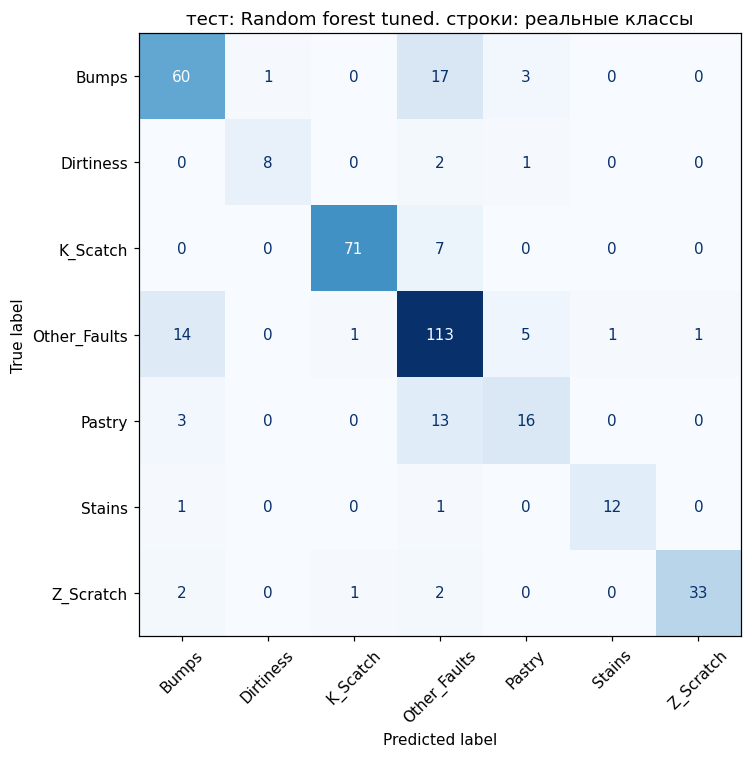

In [13]:
final_models = {'LR C=1 reference': logistic().fit(X_train, y_train), 'LR tuned C': lr_search.best_estimator_, chosen_name: chosen_model}
(test_predictions, test_rows) = ({}, {})
for (name, model) in final_models.items():
    pred = model.predict(X_test)
    test_predictions[name] = pred
    test_rows[name] = {'accuracy': accuracy_score(y_test, pred), 'balanced_accuracy': balanced_accuracy_score(y_test, pred), 'precision_macro': precision_score(y_test, pred, average='macro', zero_division=0), 'recall_macro': recall_score(y_test, pred, average='macro', zero_division=0), 'f1_macro': f1_score(y_test, pred, average='macro', zero_division=0)}
test_table = pd.DataFrame(test_rows).T
display(test_table.round(4))
pred = test_predictions[chosen_name]
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
display(report.round(4))
(fig, ax) = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, xticks_rotation=45, cmap='Blues', colorbar=False, ax=ax)
ax.set_title(f'тест: {chosen_name}. строки: реальные классы')
fig.tight_layout()
plt.show()
h4_delta = test_rows['LR tuned C']['f1_macro'] - test_rows['LR C=1 reference']['f1_macro']
h4_ok = h4_delta > 0

4: не подтвердилась, c=100, снижение f1 macro 0,0282 относительно c=1

итог: случайный лес

f1 macro 0,8046

accuracy 0,8046

balanced accuracy 0,7773

pastry recall 0,5